Dataset Shape: (1200, 2)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 769 (3.00 KB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.6497 - loss: 0.6817 - val_accuracy: 0.7708 - val_loss: 0.6449
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8203 - loss: 0.5878 - val_accuracy: 0.7708 - val_loss: 0.5662
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.8672 - loss: 0.4905 - val_accuracy: 0.7917 - val_loss: 0.4838
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8750 - loss: 0.4024 - val_accuracy: 0.8073 - val_loss: 0.4180
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8776 - loss: 0.3433 - val_accuracy: 0.8385 - val_loss: 0.3826
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8763 - loss: 0.3143 - val_accuracy: 0.8385 - val_loss: 0.3696
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8789 - loss: 0.3016 - val_accuracy: 0.8385 - val_loss: 0.3656
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8815 - loss: 0.2951 - val_accuracy: 0.83

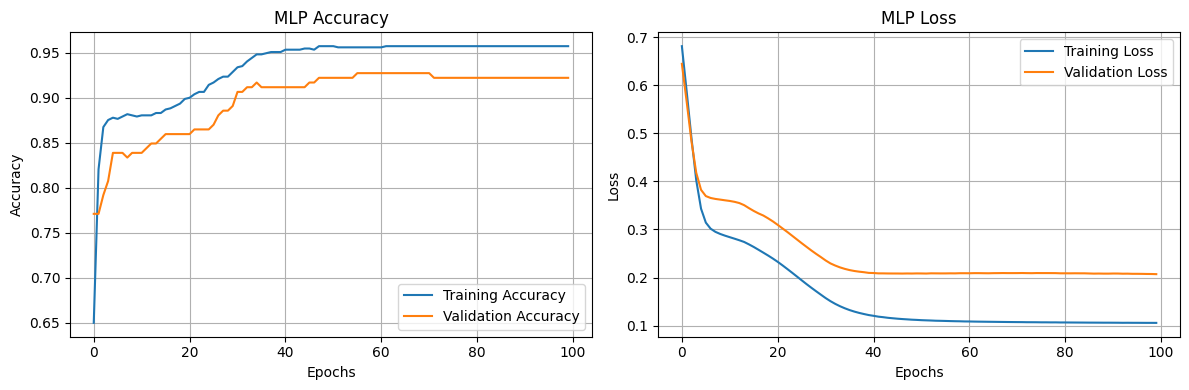

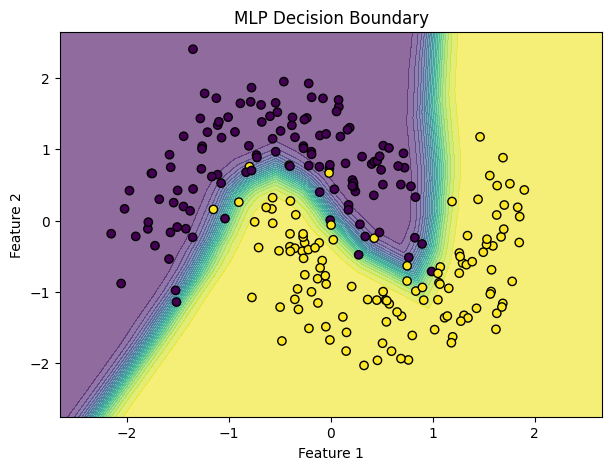

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate dataset
X, y = make_moons(
    n_samples=1200,
    noise=0.22,
    random_state=42
)

print("Dataset Shape:", X.shape)

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Normalize features
scaler = StandardScaler()

X_train = scaler.fit_transform(
    X_train
).astype("float32")

X_test = scaler.transform(
    X_test
).astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

# 4. Build MLP model
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(2,)),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        16,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        8,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

# 5. Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
model.summary()

# 6. Train model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 7. Evaluate model
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nMODEL EVALUATION")

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

# 8. Make predictions
predictions = model.predict(
    X_test[:10],
    verbose=0
)

print("\nSAMPLE PREDICTIONS")

for i in range(10):

    predicted_class = int(
        predictions[i][0] >= 0.5
    )

    print(
        "Sample:", i+1,
        "Probability:", predictions[i][0],
        "Predicted:", predicted_class,
        "Actual:", int(y_test[i])
    )

# 9. Plot accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MLP Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("MLP Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# 10. Decision boundary visualization
x_min = X_train[:, 0].min() - 0.5
x_max = X_train[:, 0].max() + 0.5

y_min = X_train[:, 1].min() - 0.5
y_max = X_train[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[
    xx.ravel(),
    yy.ravel()
].astype("float32")

Z = model.predict(
    grid,
    verbose=0
)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(7, 5))

plt.contourf(
    xx,
    yy,
    Z,
    levels=20,
    alpha=0.6
)

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.title("MLP Decision Boundary")

plt.show()